In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns

# Visual configurations
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10

In [3]:
# 1. Resolve paths
data_dir = Path("../data")
classes_path = data_dir / "elliptic_txs_classes.csv"
edgelist_path = data_dir / "elliptic_txs_edgelist.csv"
features_path = data_dir / "elliptic_txs_features.csv"

for p in [classes_path, edgelist_path, features_path]:
    if not p.exists():
        raise FileNotFoundError(f"Missing file: {p.resolve()}")

In [4]:
# 2. Ingest class labels
# Mapping: 1 = Illicit, 2 = Licit, "unknown" = Unlabeled
classes_df = pd.read_csv(classes_path)
classes_df["txId"] = classes_df["txId"].astype(np.int64)

# 3. Construct explicit column schema for features (167 columns total: txId + time_step + 165 features)
feature_cols = (
    ["txId", "time_step"]
    + [f"local_feat_{i}" for i in range(1, 94)]
    + [f"agg_feat_{i}" for i in range(1, 73)]
)

print("Loading transaction feature matrix (this may take ~10-15 seconds)...")
features_df = pd.read_csv(features_path, header=None, names=feature_cols)
features_df["txId"] = features_df["txId"].astype(np.int64)
features_df["time_step"] = features_df["time_step"].astype(int)

Loading transaction feature matrix (this may take ~10-15 seconds)...


In [5]:
# 4. Ingest directed transaction flow edgelist
edges_df = pd.read_csv(edgelist_path)
edges_df["txId1"] = edges_df["txId1"].astype(np.int64)
edges_df["txId2"] = edges_df["txId2"].astype(np.int64)

# 5. Merge node features with class ground truth
tx_nodes_df = features_df.merge(classes_df, on="txId", how="inner")

# Standardize class column: map '1' -> 1 (illicit), '2' -> 0 (licit), 'unknown' -> -1 / NaN
tx_nodes_df["class_label"] = tx_nodes_df["class"].map({"1": 1, "2": 0, "unknown": -1})

In [6]:
# Print dataset diagnostics
print("=" * 70)
print(f"Total Transactions (Nodes): {len(tx_nodes_df):,}")
print(f"Total Payment Flows (Edges): {len(edges_df):,}")
print(f"Total Temporal Steps:       {tx_nodes_df['time_step'].nunique()} (Range: {tx_nodes_df['time_step'].min()} - {tx_nodes_df['time_step'].max()})")
print("=" * 70)
print("\nClass Label Breakdown:")
display(tx_nodes_df["class"].value_counts(dropna=False).to_frame("count").assign(
    percentage=lambda df: (df["count"] / df["count"].sum() * 100).round(2).astype(str) + "%"
))

Total Transactions (Nodes): 203,769
Total Payment Flows (Edges): 234,355
Total Temporal Steps:       49 (Range: 1 - 49)

Class Label Breakdown:


,count,percentage
class,,
unknown,157205,77.15%
2,42019,20.62%
1,4545,2.23%


Temporal Distribution & Structural Drift Analysis

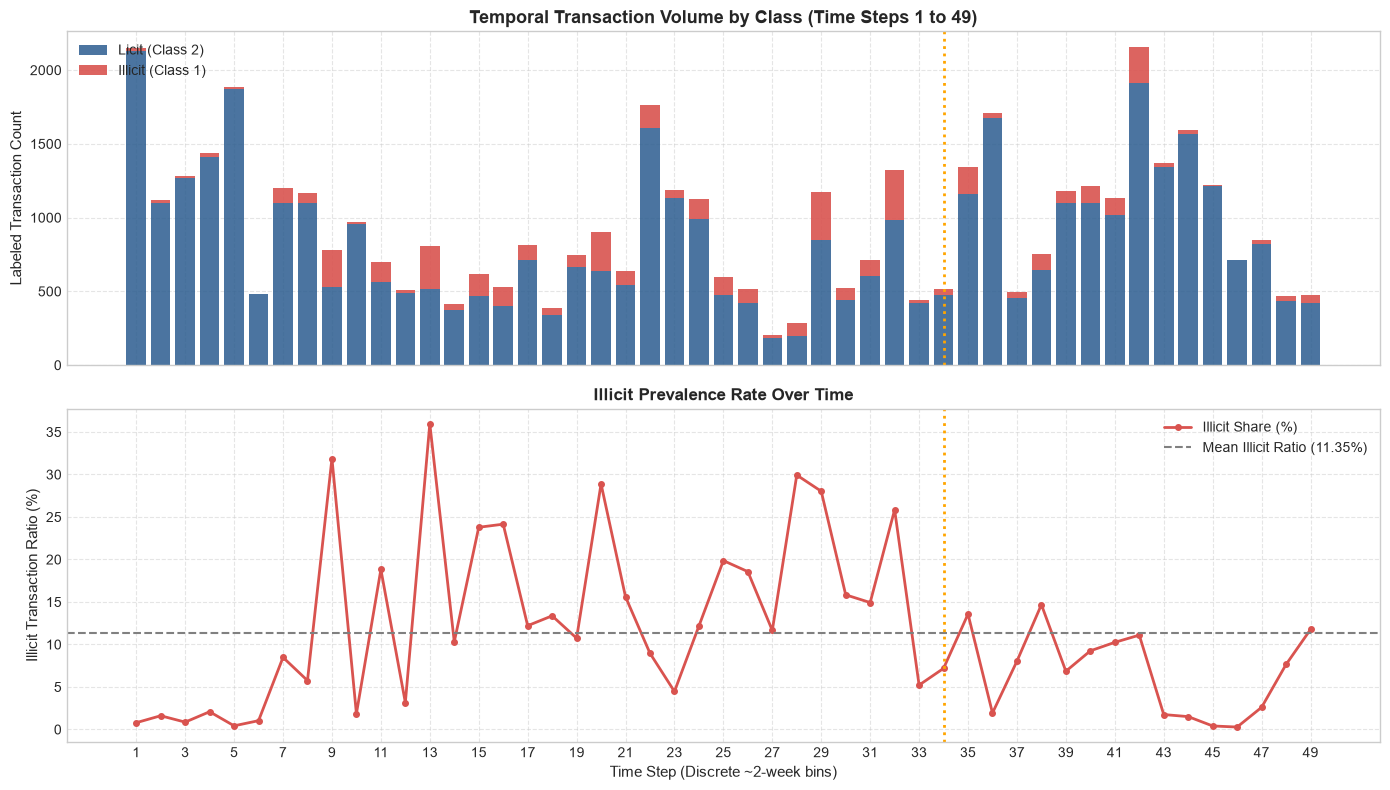

class,licit,illicit,total_labeled,illicit_ratio_pct
time_step,,,,
13,518,291,809,35.97%
9,530,248,778,31.88%
28,199,85,284,29.93%
20,640,260,900,28.89%
29,845,329,1174,28.02%


In [7]:
# 1. Aggregate counts per time step for labeled transactions
temporal_summary = (
    tx_nodes_df[tx_nodes_df["class"].isin(["1", "2"])]
    .groupby(["time_step", "class"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={"1": "illicit", "2": "licit"})
)

temporal_summary["total_labeled"] = temporal_summary["illicit"] + temporal_summary["licit"]
temporal_summary["illicit_ratio_pct"] = (
    temporal_summary["illicit"] / temporal_summary["total_labeled"] * 100
)

# 2. Add unlabeled (unknown) volume for context
temporal_summary["unknown"] = (
    tx_nodes_df[tx_nodes_df["class"] == "unknown"]
    .groupby("time_step")
    .size()
)

# 3. Plot stacked temporal volume & illicit proportion
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Top Subplot: Volume Breakdown (Licit vs Illicit)
ax1.bar(
    temporal_summary.index,
    temporal_summary["licit"],
    label="Licit (Class 2)",
    color="#2b5c8f",
    alpha=0.85
)
ax1.bar(
    temporal_summary.index,
    temporal_summary["illicit"],
    bottom=temporal_summary["licit"],
    label="Illicit (Class 1)",
    color="#d9534f",
    alpha=0.9
)
ax1.set_ylabel("Labeled Transaction Count", fontsize=11)
ax1.set_title("Temporal Transaction Volume by Class (Time Steps 1 to 49)", fontsize=13, fontweight="bold")
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.5)

# Highlight known structural shift (Step ~34)
ax1.axvline(x=34, color="orange", linestyle=":", linewidth=2, label="Darknet Market Disruption (~Step 34)")

# Bottom Subplot: Illicit Proportion Curve
ax2.plot(
    temporal_summary.index,
    temporal_summary["illicit_ratio_pct"],
    color="#d9534f",
    marker="o",
    linewidth=2,
    markersize=4,
    label="Illicit Share (%)"
)
ax2.axhline(
    y=temporal_summary["illicit_ratio_pct"].mean(),
    color="gray",
    linestyle="--",
    label=f"Mean Illicit Ratio ({temporal_summary['illicit_ratio_pct'].mean():.2f}%)"
)
ax2.axvline(x=34, color="orange", linestyle=":", linewidth=2)
ax2.set_xlabel("Time Step (Discrete ~2-week bins)", fontsize=11)
ax2.set_ylabel("Illicit Transaction Ratio (%)", fontsize=11)
ax2.set_title("Illicit Prevalence Rate Over Time", fontsize=12, fontweight="bold")
ax2.set_xticks(range(1, 50, 2))
ax2.legend(loc="upper right")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 4. Display high/low outlier time steps
display(
    temporal_summary[["licit", "illicit", "total_labeled", "illicit_ratio_pct"]]
    .sort_values("illicit_ratio_pct", ascending=False)
    .head(5)
    .style.format({"illicit_ratio_pct": "{:.2f}%"})
)

Directed Graph Topology, Degree Dynamics & Flow Anomaly Extraction

Constructing directed transaction graph from edge flows...
Graph initialized: 203,769 nodes and 234,355 directed edges

Degree Distribution Summary (Illicit vs. Licit):


in_degree                       out_degree                        \
                 mean median       std  max       mean median       std  max   
label_name                                                                     
Illicit (1)  1.269967    1.0  7.215218  177   0.741694    1.0  0.571620    3   
Licit (2)    1.909398    1.0  7.122538  284   1.185821    1.0  3.246769  472   

            total_degree                        
                    mean median       std  max  
label_name                                      
Illicit (1)     2.011661    1.0  7.177521  177  
Licit (2)       3.095219    2.0  7.782942  473

c:\Users\lxx55\crypto-forensics-illicit-detection\.venv\Lib\site-packages\pandas\core\nanops.py:1324: RuntimeWarning: invalid value encountered in subtract
  sqr = (avg - values) ** 2
C:\Users\lxx55\AppData\Local\Temp\ipykernel_5956\88633315.py:38: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(
c:\Users\lxx55\crypto-forensics-illicit-detection\.venv\Lib\site-packages\pandas\core\nanops.py:1324: RuntimeWarning: invalid value encountered in subtract
  sqr = (avg - values) ** 2
C:\Users\lxx55\AppData\Local\Temp\ipykernel_5956\88633315.py:38: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


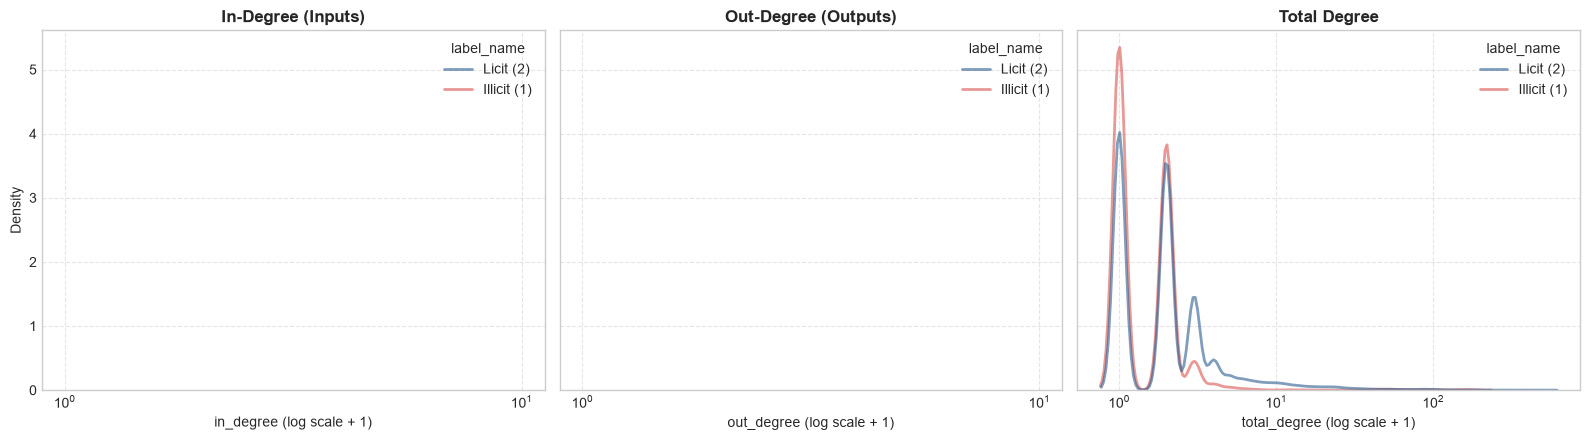

99.5th percentile degree threshold: >= 47 connections


,Share in High-Degree Anomalies (%)
label_name,
Licit (2),91.8
Illicit (1),8.2


In [8]:
# 1. Build directed transaction graph using NetworkX
print("Constructing directed transaction graph from edge flows...")
G = nx.from_pandas_edgelist(
    edges_df,
    source="txId1",
    target="txId2",
    create_using=nx.DiGraph()
)

print(f"Graph initialized: {G.number_of_nodes():,} nodes and {G.number_of_edges():,} directed edges")

# 2. Extract in-degree, out-degree, and total degree
in_degrees = dict(G.in_degree())
out_degrees = dict(G.out_degree())

# Map degree metrics onto the primary node dataframe
tx_nodes_df["in_degree"] = tx_nodes_df["txId"].map(in_degrees).fillna(0).astype(int)
tx_nodes_df["out_degree"] = tx_nodes_df["txId"].map(out_degrees).fillna(0).astype(int)
tx_nodes_df["total_degree"] = tx_nodes_df["in_degree"] + tx_nodes_df["out_degree"]

# 3. Filter labeled cohort for topological comparison
labeled_cohort = tx_nodes_df[tx_nodes_df["class"].isin(["1", "2"])].copy()
labeled_cohort["label_name"] = labeled_cohort["class"].map({"1": "Illicit (1)", "2": "Licit (2)"})

# 4. Display comparative summary statistics
degree_summary = labeled_cohort.groupby("label_name")[["in_degree", "out_degree", "total_degree"]].agg(
    ["mean", "median", "std", "max"]
)
print("\nDegree Distribution Summary (Illicit vs. Licit):")
display(degree_summary)

# 5. Visualizing Degree Distributions (Log-Scale)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

metrics = [("in_degree", "In-Degree (Inputs)"), ("out_degree", "Out-Degree (Outputs)"), ("total_degree", "Total Degree")]

for ax, (metric, title) in zip(axes, metrics):
    sns.kdeplot(
        data=labeled_cohort,
        x=metric,
        hue="label_name",
        common_norm=False,
        log_scale=(True, False),
        palette={"Illicit (1)": "#d9534f", "Licit (2)": "#2b5c8f"},
        alpha=0.6,
        linewidth=2,
        ax=ax
    )
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{metric} (log scale + 1)", fontsize=10)
    ax.set_ylabel("Density" if ax == axes[0] else "", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 6. High-Degree Flow Anomaly Detection
# Isolate transactions in the top 99.5th percentile of connectivity
high_degree_threshold = labeled_cohort["total_degree"].quantile(0.995)
print(f"99.5th percentile degree threshold: >= {high_degree_threshold:.0f} connections")

high_degree_anomalies = labeled_cohort[labeled_cohort["total_degree"] >= high_degree_threshold]
display(
    high_degree_anomalies["label_name"]
    .value_counts(normalize=True)
    .mul(100)
    .to_frame("Share in High-Degree Anomalies (%)")
    .round(2)
)

Export Curated Parquet Artifacts

In [9]:
# 1. Define export paths
output_dir = Path("../data")
clean_nodes_parquet = output_dir / "elliptic_txs_enriched.parquet"
clean_labeled_parquet = output_dir / "elliptic_txs_labeled.parquet"

# 2. Select and order columns
feature_columns = (
    ["txId", "time_step", "class", "class_label", "in_degree", "out_degree", "total_degree"]
    + [f"local_feat_{i}" for i in range(1, 94)]
    + [f"agg_feat_{i}" for i in range(1, 73)]
)

# 3. Export complete node matrix (includes 'unknown' for potential semi-supervised/GNN use)
print("Exporting full enriched transaction cohort to Parquet...")
tx_nodes_df[feature_columns].to_parquet(
    clean_nodes_parquet,
    index=False,
    compression="snappy"
)

# 4. Export labeled cohort only (primary dataset for supervised learning & AML baselines)
print("Exporting labeled-only transaction cohort to Parquet...")
labeled_cohort = tx_nodes_df[tx_nodes_df["class_label"].isin([0, 1])][feature_columns].copy()
labeled_cohort["class_label"] = labeled_cohort["class_label"].astype(np.int8)

labeled_cohort.to_parquet(
    clean_labeled_parquet,
    index=False,
    compression="snappy"
)

# 5. Verify exported file sizes and row counts
print("\n" + "=" * 70)
print("EXPORT ARTIFACT SUMMARY")
print("=" * 70)
print(f"Enriched Full Dataset:    {clean_nodes_parquet.name:<30} | {len(tx_nodes_df):>8,} rows | {clean_nodes_parquet.stat().st_size / (1024*1024):>6.2f} MB")
print(f"Supervised Labeled Cohort: {clean_labeled_parquet.name:<30} | {len(labeled_cohort):>8,} rows | {clean_labeled_parquet.stat().st_size / (1024*1024):>6.2f} MB")
print("=" * 70)
print("Artifact generation complete. Ready to proceed to Notebook 2.")

Exporting full enriched transaction cohort to Parquet...
Exporting labeled-only transaction cohort to Parquet...

EXPORT ARTIFACT SUMMARY
Enriched Full Dataset:    elliptic_txs_enriched.parquet  |  203,769 rows |  90.53 MB
Supervised Labeled Cohort: elliptic_txs_labeled.parquet   |   46,564 rows |  24.40 MB
Artifact generation complete. Ready to proceed to Notebook 2.
